In [2]:
import matplotlib 
import matplotlib.pyplot as plt
%matplotlib inline

import numpy as np 

In [4]:
import pandas as pd
url = "data/nhanes_2015_2016.csv"
da = pd.read_csv(url)
da

,SEQN,ALQ101,ALQ110,ALQ130,SMQ020,RIAGENDR,RIDAGEYR,RIDRETH1,DMDCITZN,DMDEDUC2,...,BPXSY2,BPXDI2,BMXWT,BMXHT,BMXBMI,BMXLEG,BMXARML,BMXARMC,BMXWAIST,HIQ210
0,83732,1.0,NaN,1.0,1,1,62,3,1.0,5.0,...,124.0,64.0,94.8,184.5,27.8,43.3,43.6,35.9,101.1,2.0
1,83733,1.0,NaN,6.0,1,1,53,3,2.0,3.0,...,140.0,88.0,90.4,171.4,30.8,38.0,40.0,33.2,107.9,NaN
2,83734,1.0,NaN,NaN,1,1,78,3,1.0,3.0,...,132.0,44.0,83.4,170.1,28.8,35.6,37.0,31.0,116.5,2.0
3,83735,2.0,1.0,1.0,2,2,56,3,1.0,5.0,...,134.0,68.0,109.8,160.9,42.4,38.5,37.7,38.3,110.1,2.0
4,83736,2.0,1.0,1.0,2,2,42,4,1.0,4.0,...,114.0,54.0,55.2,164.9,20.3,37.4,36.0,27.2,80.4,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5730,93695,2.0,2.0,NaN,1,2,76,3,1.0,3.0,...,112.0,46.0,59.1,165.8,21.5,38.2,37.0,29.5,95.0,2.0
5731,93696,2.0,2.0,NaN,2,1,26,3,1.0,5.0,...,116.0,76.0,112.1,182.2,33.8,43.4,41.8,42.3,110.2,2.0
5732,93697,1.0,NaN,1.0,1,2,80,3,1.0,4.0,...,146.0,58.0,71.7,152.2,31.0,31.3,37.5,28.8,NaN,2.0
5733,93700,NaN,NaN,NaN,1,1,35,3,2.0,1.0,...,106.0,66.0,78.2,173.3,26.0,40.3,37.5,30.6,98.9,2.0


# Studying Discrete Values 

In [8]:
gender = da['RIAGENDR']
gender.value_counts()

RIAGENDR
2    2976
1    2759
Name: count, dtype: int64

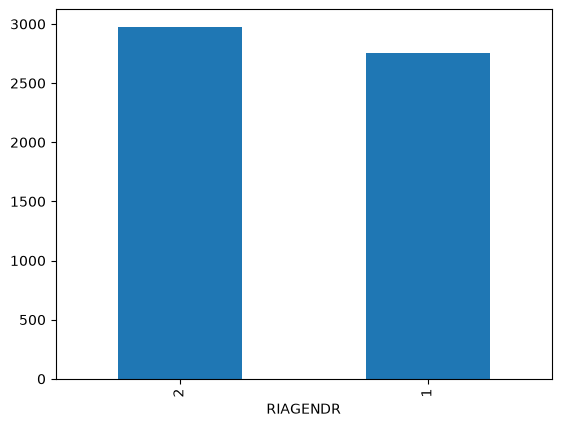

In [9]:
gender.value_counts().plot(kind='bar')
plt.show()

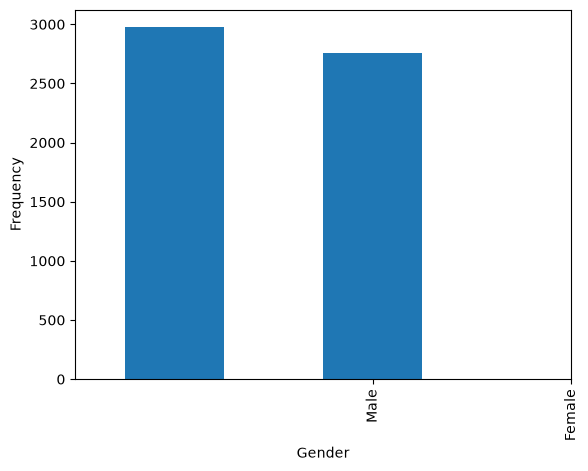

In [12]:
gender.value_counts().plot(kind='bar')
plt.xticks([1, 2], ['Male', 'Female'])
plt.xlabel("Gender")
plt.ylabel("Frequency")
plt.show()

### Most Common Value

In [13]:
sizes = np.array([22, 23, 29, 32, 39, 42, 42, 42, 42, 42, 42, 42, 42, 43, 44, 46, 51, 51, 55, 55, 57, 58, 78, 83, 97, 97])

In [14]:
sizes.mean()

np.float64(49.84615384615385)

In [15]:
!pip install scipy

In [16]:
from scipy import stats
stats.mode(sizes)    # index 0 has value, index 1 has count 

ModeResult(mode=np.int64(42), count=np.int64(8))

In [18]:
gender.mode()   # not too useful since we could have got that from the bar chart anyway

0    2
Name: RIAGENDR, dtype: int64

In [17]:
stats.mode(gender) 

ModeResult(mode=np.int64(2), count=np.int64(2976))

### More than One "Classes "

In [19]:
da['HIQ210'].unique()

array([ 2., nan,  1.,  9.])

In [20]:
da['HIQ210'].value_counts()

HIQ210
2.0    4268
1.0     456
9.0       8
Name: count, dtype: int64

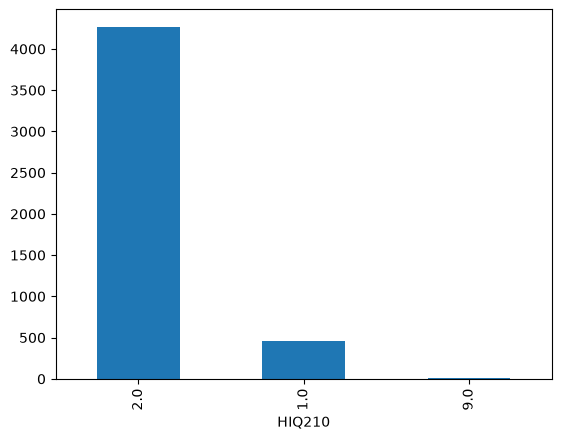

In [21]:
da['HIQ210'].value_counts().plot(kind='bar')
plt.show()

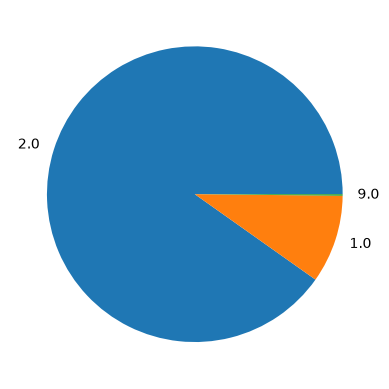

In [22]:
da['HIQ210'].value_counts().plot(kind='pie')  # highly NOT recommended! 
plt.show()

# Studying Real-Valued Numbers 

In [24]:
wt = da['BMXWT']

In [25]:
wt 

0        94.8
1        90.4
2        83.4
3       109.8
4        55.2
        ...  
5730     59.1
5731    112.1
5732     71.7
5733     78.2
5734     58.3
Name: BMXWT, Length: 5735, dtype: float64

In [27]:
wt.value_counts().unique()

array([20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10,  9,  8,  7,  6,  5,  4,
        3,  2,  1])

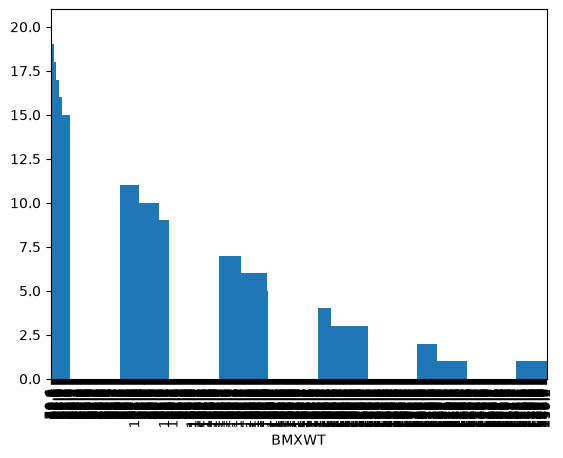

In [29]:
wt.value_counts().plot(kind='bar')    # this does not work at all 
plt.show()

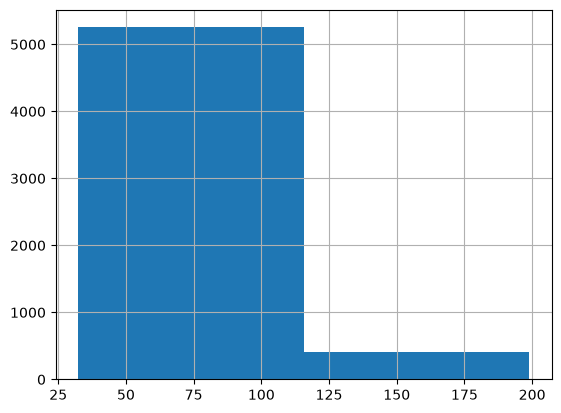

In [31]:
wt.hist(bins=2)
plt.show()

### Custom Matplotlib Histogram 

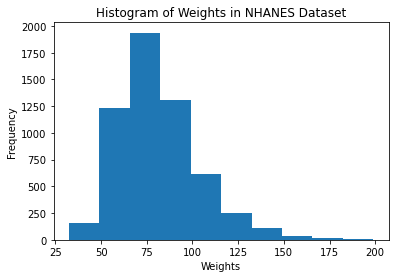

In [19]:
plt.hist(wt, bins=10) 
plt.ylabel('Frequency')
plt.xlabel('Weights');
plt.title("Histogram of Weights in NHANES Dataset")
plt.show()

### Prettifying and Styling Matplotlib with Seaborn

In [32]:
!pip install seaborn

In [34]:
import seaborn as sns
sns.set(color_codes=True)
sns.set_style("white")     # See more styling options here: https://seaborn.pydata.org/tutorial/aesthetics.html

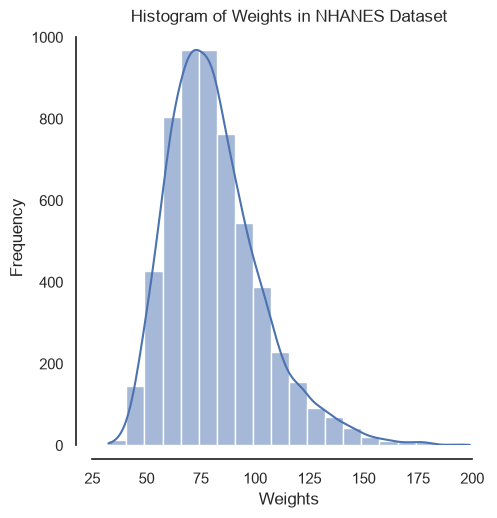

In [39]:
sns.displot(wt, bins=20, kde=True )   # to get rid of the "trend line"
plt.ylabel('Frequency')
plt.xlabel('Weights');
plt.title("Histogram of Weights in NHANES Dataset")
sns.despine(offset=10, trim=True);  # move axes away 
plt.show()

See many more options about histograms with seaborn here: https://seaborn.pydata.org/tutorial/distributions.html

### Studying Central Tendency 

(0, 6000) (75, 75)


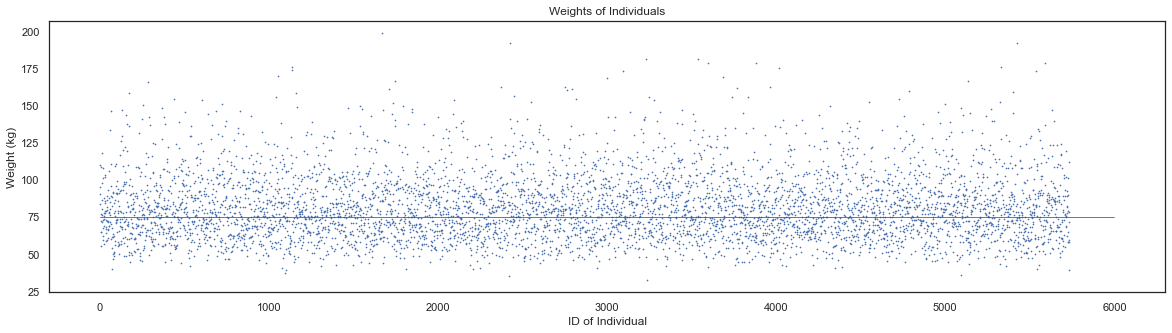

In [23]:
plt.figure(figsize=(20, 5)) 

x =  range(da['BMXWT'].size)
y =  da['BMXWT']

plt.scatter(x, y, marker='x', s=0.5)

plt.title("Weights of Individuals")
plt.xlabel("ID of Individual")
plt.ylabel("Weight (kg)")

# plot the estimate line 
p1 = (0, 75)
p2 = (6000, 75)
x_c, y_c = zip(p1, p2)
print(x_c, y_c)
plt.plot(x_c, y_c, color='red', linewidth=0.75)
plt.show()

In [40]:
wt.mean() 

np.float64(81.34267560889516)

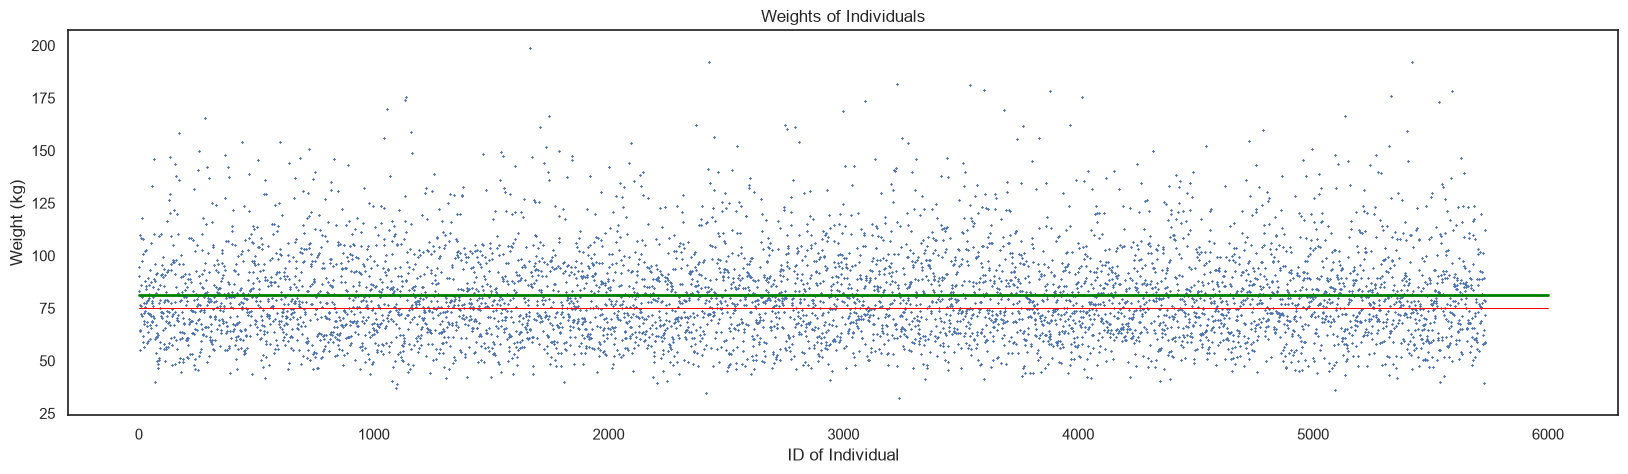

In [41]:
plt.figure(figsize=(20, 5)) 

x =  range(da['BMXWT'].size)
y =  da['BMXWT']

plt.scatter(x, y, marker='x', s=0.5)

plt.title("Weights of Individuals")
plt.xlabel("ID of Individual")
plt.ylabel("Weight (kg)")

# plot the estimate line 
x_c, y_c = ([0, 6000], [75, 75])
plt.plot(x_c, y_c, color='red', linewidth=0.75)

# plot the estimate line 
x_c, y_c = ([0, 6000], [wt.mean(), wt.mean()])
plt.plot(x_c, y_c, color='green', linewidth=2)

plt.show()

## Problem with Arithmetic Mean 

In [42]:
import numpy as np 

In [43]:
nums = np.array( [3, 4, 9, 17, 18, 20, 22, 23, 29, 32, 39, 42, 42, 42, 51, 97] )

In [44]:
np.mean(nums)

np.float64(30.625)

In [45]:
# let's try to do a different kind of average: the median! 
np.median(nums)

np.float64(26.0)

## Visualizing Weights Data 
The problem with our weights data is similar. 

In [48]:
wt

0        94.8
1        90.4
2        83.4
3       109.8
4        55.2
        ...  
5730     59.1
5731    112.1
5732     71.7
5733     78.2
5734     58.3
Name: BMXWT, Length: 5735, dtype: float64

In [49]:
wt.max()

np.float64(198.9)

In [50]:
wt.min()

np.float64(32.4)

In [51]:
wt.median()

np.float64(78.2)

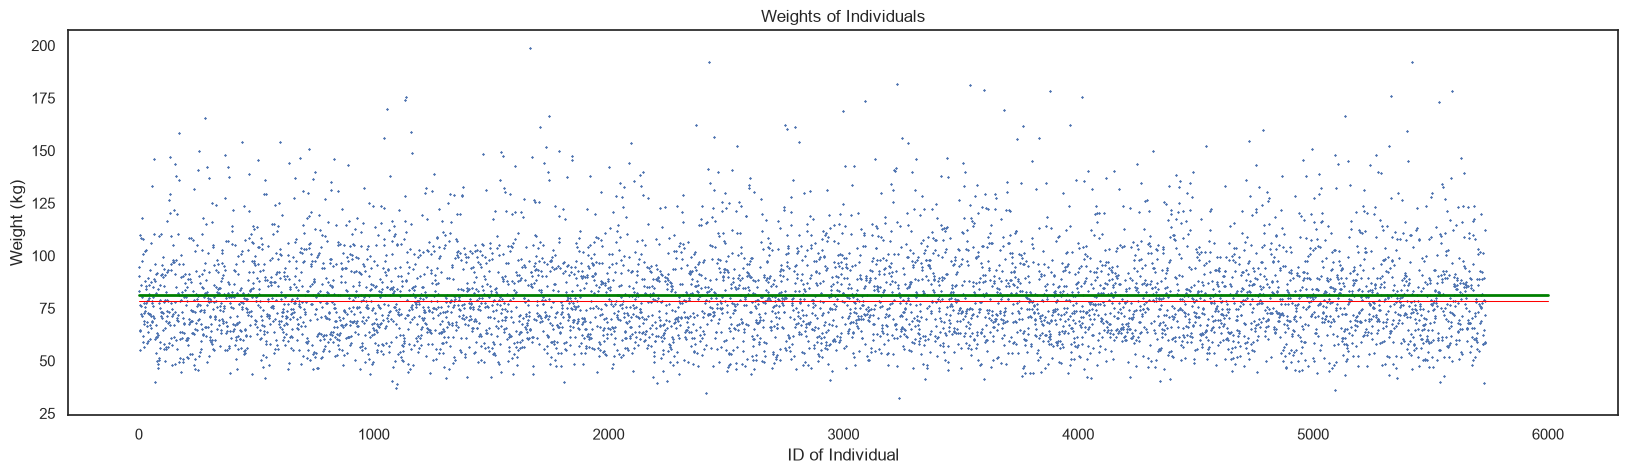

In [52]:
plt.figure(figsize=(20, 5)) 

x =  range(da['BMXWT'].size)
y =  da['BMXWT']

plt.scatter(x, y, marker='x', s=0.5)

plt.title("Weights of Individuals")
plt.xlabel("ID of Individual")
plt.ylabel("Weight (kg)")

# plot the estimate line 
x_c, y_c = ([0, 6000], [wt.median(), wt.median()])
plt.plot(x_c, y_c, color='red', linewidth=0.75)

# plot the estimate line 
x_c, y_c = ([0, 6000], [wt.mean(), wt.mean()])
plt.plot(x_c, y_c, color='green', linewidth=2)

plt.show()

### Quartiles and Boxplots 

In [53]:
nums = np.array([3, 4, 9, 17, 18, 20, 22, 23, 29, 32, 39, 42, 42, 42, 51, 97])

In [54]:
np.median(nums)

np.float64(26.0)

In [55]:
import statistics 

In [56]:
statistics.quantiles(nums, n=4)

[np.float64(17.25), np.float64(26.0), np.float64(42.0)]

In [57]:
statistics.quantiles(wt, n=4)

[43.7, 52.5, 50.1]

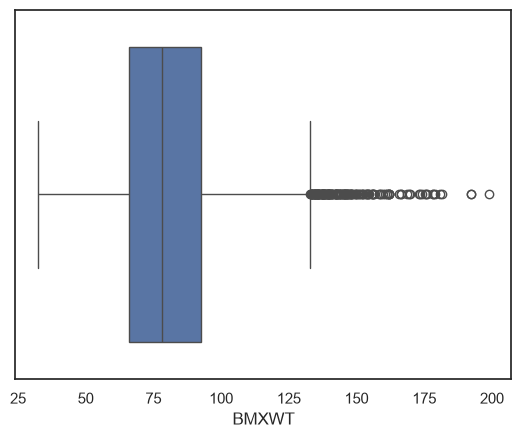

In [58]:
ax = sns.boxplot(x=wt)

In [48]:
male_wt = da.loc[   da['RIAGENDR'] == 1, 'BMXWT'   ]         
male_wt.mean()             # try .mean() 

86.57326222876058

In [49]:
female_wt = da.loc[da['RIAGENDR'] == 2, 'BMXWT']
female_wt.mean()

76.51676280963693

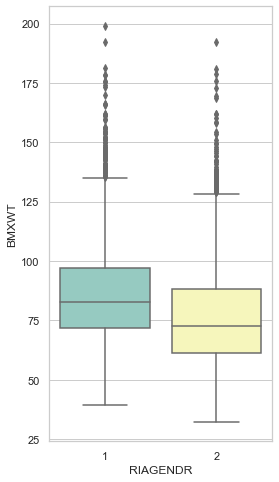

In [50]:
# But there's an easier way 
plt.figure(figsize=(4,8))
sns.set_style("whitegrid") 

ax = sns.boxplot(  x = "RIAGENDR", y = "BMXWT",           data=da               , palette="Set3")

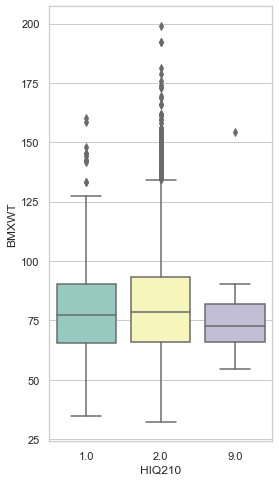

In [51]:
# But there's an easier way 
plt.figure(figsize=(4,8))
sns.set_style("whitegrid") 


ax = sns.boxplot(  x = "HIQ210", y = "BMXWT",           data=da               , palette="Set3")